# Detección de SMS spam con una red convolucional
**Iris Giselle Balderas Arreola · A01752895**

## Introducción
Se planteó clasificar mensajes SMS en inglés como legítimos (`ham`) o no solicitados (`spam`). El filtrado puede disminuir distracciones y ayudar a detectar mensajes sospechosos, aunque un clasificador no demuestra que un mensaje sea seguro o fraudulento.

Se eligió **SMS Spam Collection**, publicado en Kaggle por UCI ML. Se trata de mensajes reales recopilados para investigación, no de un dataset sintético o de juguete. Es pequeño en descarga y permite entrenar una CNN sin modelos preentrenados. No se encontró este dataset en las diapositivas proporcionadas; esto no permite verificar ejercicios de clase que no estén incluidos en ellas.

Se aplicaron convoluciones, pooling, Adam, dropout y early stopping. Las convoluciones se usaron sobre secuencias de palabras en lugar de imágenes: cada filtro detecta patrones locales de varias palabras.


In [1]:
# Se configuraron las semillas y el uso de CPU para una ejecución ligera.
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"
os.environ["TF_NUM_INTRAOP_THREADS"] = "2"
os.environ["TF_NUM_INTEROP_THREADS"] = "2"
from pathlib import Path
import json, time, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             average_precision_score, classification_report,
                             ConfusionMatrixDisplay, precision_recall_curve)
from IPython.display import display, Markdown
SEED = 42
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
BASE = Path.cwd()
for carpeta in ["datos", "modelos", "resultados"]:
    (BASE / carpeta).mkdir(exist_ok=True)
print("TensorFlow:", tf.__version__)
print("Dispositivos:", tf.config.list_physical_devices("CPU"))

TensorFlow: 2.20.0
Dispositivos: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


## Datos
Fuente seleccionada: https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset

Fuente original y descripción: https://archive.ics.uci.edu/dataset/228/sms+spam+collection

Referencia: Almeida, T. y Hidalgo, J. (2011). *SMS Spam Collection*. DOI: https://doi.org/10.24432/C5CC84. La fuente original indica licencia CC BY 4.0. Se conservó el CSV descargado de Kaggle y su atribución.

Se usaron `v1` (clase) y `v2` (texto). Se eliminaron vacíos y mensajes repetidos después de convertir a minúsculas, quitar puntuación y normalizar espacios, siguiendo la normalización de la vectorización. Si un mismo texto tiene etiquetas contradictorias, se retira el grupo completo. Esto reduce fuga por duplicados, aunque pueden quedar plantillas muy similares.


In [2]:
# Se descargó el archivo de Kaggle solamente si no estaba disponible.
import urllib.request, zipfile, io
archivo = BASE / "datos/spam.csv"
if not archivo.exists():
    url = "https://www.kaggle.com/api/v1/datasets/download/uciml/sms-spam-collection-dataset"
    peticion = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(peticion, timeout=60) as respuesta:
        contenido = respuesta.read()
    with zipfile.ZipFile(io.BytesIO(contenido)) as comprimido:
        archivo.write_bytes(comprimido.read("spam.csv"))
print("Archivo:", archivo.name, "| bytes:", archivo.stat().st_size)
print("SHA256:", hashlib.sha256(archivo.read_bytes()).hexdigest())
datos = pd.read_csv(archivo, encoding="latin-1")[["v1", "v2"]]
datos.columns = ["clase", "texto"]
iniciales = len(datos)
datos = datos.dropna().copy()
datos["clave"] = (datos.texto.str.lower().str.replace(r"[^\w\s]", "", regex=True)
                  .str.replace(r"_", "", regex=True).str.replace(r"\s+", " ", regex=True).str.strip())
datos = datos[datos.clave.ne("")]
conflictos = datos.groupby("clave").clase.nunique()
datos = datos[~datos.clave.isin(conflictos[conflictos > 1].index)]
datos = datos.drop_duplicates("clave").reset_index(drop=True)
assert set(datos.clase) == {"ham", "spam"}
datos["etiqueta"] = datos.clase.map({"ham": 0, "spam": 1})
print("Filas originales:", iniciales, "| utilizadas:", len(datos), "| retiradas:", iniciales-len(datos))
display(datos[["clase", "texto"]].head())
display(datos.groupby("clase").agg(mensajes=("texto", "size")))

Archivo: spam.csv | bytes: 503663
SHA256: 440e6ea9fa825578abfdd7b7932ef8393d72ef86c0c33f64676705ce40b1dfc2
Filas originales: 5572 | utilizadas: 5129 | retiradas: 443


,clase,texto
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


,mensajes
clase,
ham,4497
spam,632


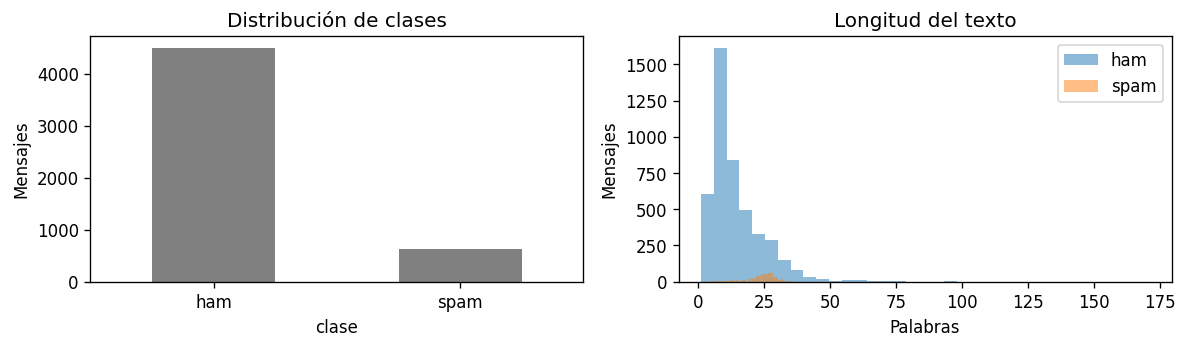

In [3]:
# Se revisaron el desbalance y la longitud de los mensajes.
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
datos.clase.value_counts().plot.bar(ax=ax[0], color="gray", rot=0)
ax[0].set(title="Distribución de clases", ylabel="Mensajes")
for clase in ["ham", "spam"]:
    datos.loc[datos.clase.eq(clase), "texto"].str.split().str.len().plot.hist(
        bins=35, alpha=0.5, ax=ax[1], label=clase)
ax[1].set(title="Longitud del texto", xlabel="Palabras", ylabel="Mensajes")
ax[1].legend()
plt.tight_layout()
plt.savefig(BASE / "resultados/exploracion.png", dpi=140)
plt.show()

Se realizó una separación estratificada de aproximadamente **70% entrenamiento, 15% validación y 15% prueba**. El vocabulario se aprendió únicamente del entrenamiento. La validación se utilizó para comparar las dos configuraciones y elegir la época. Prueba permaneció fuera de esas decisiones.

Se fijaron 6,000 tokens como máximo y secuencias de 80 tokens. Los mensajes más largos se truncan y los más cortos se rellenan. Como hay menos spam, se priorizó F1 de spam en la comparación y también se reportaron precisión, recall y average precision (AP). Se mantuvo el umbral 0.5 en ambos modelos.


In [4]:
# Se separaron los conjuntos antes de aprender el vocabulario.
entreno, temporal = train_test_split(datos, test_size=0.30, random_state=SEED, stratify=datos.etiqueta)
validacion, prueba = train_test_split(temporal, test_size=0.50, random_state=SEED, stratify=temporal.etiqueta)
assert set(entreno.clave).isdisjoint(validacion.clave)
assert set(entreno.clave).isdisjoint(prueba.clave)
assert set(validacion.clave).isdisjoint(prueba.clave)
particiones = pd.concat([marco.assign(conjunto=nombre) for nombre, marco in
                        [("entrenamiento", entreno), ("validación", validacion), ("prueba", prueba)]])
particiones[["clave", "conjunto"]].to_csv(BASE / "resultados/particiones.csv", index=False)
display(pd.crosstab(particiones.conjunto, particiones.clase))
print("Fracción de entrenamiento con más de 80 palabras:",
      round(entreno.texto.str.split().str.len().gt(80).mean(), 4))
vectorizador = layers.TextVectorization(max_tokens=6000, output_sequence_length=80)
vectorizador.adapt(tf.constant(entreno.texto.to_numpy()))
x_ent = vectorizador(tf.constant(entreno.texto.to_numpy())).numpy()
x_val = vectorizador(tf.constant(validacion.texto.to_numpy())).numpy()
x_test = vectorizador(tf.constant(prueba.texto.to_numpy())).numpy()
y_ent = entreno.etiqueta.to_numpy(dtype="float32")
y_val = validacion.etiqueta.to_numpy(dtype="float32")
y_test = prueba.etiqueta.to_numpy(dtype="float32")
print("Vocabulario aprendido:", vectorizador.vocabulary_size())
print("Forma del entrenamiento:", x_ent.shape)
# Se acotó el paralelismo de tf.data para funcionar también en equipos pequeños.
def conjunto(x, y, mezclar=False):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if mezclar:
        ds = ds.shuffle(len(x), seed=SEED)
    opciones = tf.data.Options()
    opciones.threading.private_threadpool_size = 1
    return ds.batch(64).with_options(opciones).prefetch(1)
ds_ent = conjunto(x_ent, y_ent, True)
ds_val = conjunto(x_val, y_val)
ds_test = conjunto(x_test, y_test)
print("Conjuntos listos.")

Fracción de entrenamiento con más de 80 palabras: 0.0017
Vocabulario aprendido: 6000
Forma del entrenamiento: (3590, 80)
Conjuntos listos.


clase,ham,spam
conjunto,,
entrenamiento,3148,442
prueba,675,95
validación,674,95


## Desarrollo del modelo
Se construyó una CNN inicial: **Embedding(32) → Conv1D(32, kernel=3, ReLU) → GlobalMaxPooling1D → Dense(1, sigmoid)**. Embedding representa palabras como vectores entrenables. Conv1D identifica combinaciones locales; pooling conserva las activaciones más fuertes. La salida estima una puntuación de spam.

Se usó entropía cruzada binaria y Adam con tasa 0.001. El modelo inicial se entrenó durante 8 épocas sin dropout. Se conservó la época de menor pérdida de validación; el modelo ajustado tendrá el mismo criterio de selección.


In [5]:
# Se implementó una arquitectura compacta con una variante regularizada.
def crear_modelo(ajustado=False):
    entrada = keras.Input(shape=(80,), dtype="int64")
    x = layers.Embedding(vectorizador.vocabulary_size(), 32)(entrada)
    if ajustado:
        x = layers.SpatialDropout1D(0.2)(x)
    x = layers.Conv1D(32, 3, activation="relu")(x)
    x = layers.GlobalMaxPooling1D()(x)
    if ajustado:
        x = layers.Dropout(0.4)(x)
    salida = layers.Dense(1, activation="sigmoid")(x)
    modelo = keras.Model(entrada, salida)
    modelo.compile(optimizer=keras.optimizers.Adam(0.001),
                   loss="binary_crossentropy", metrics=["accuracy"])
    return modelo

def medir(y, prob):
    pred = (np.asarray(prob).ravel() >= 0.5).astype(int)
    return {"accuracy": accuracy_score(y, pred),
            "precision_spam": precision_score(y, pred, zero_division=0),
            "recall_spam": recall_score(y, pred, zero_division=0),
            "f1_spam": f1_score(y, pred, zero_division=0),
            "average_precision": average_precision_score(y, np.asarray(prob).ravel())}

keras.utils.set_random_seed(SEED)
inicial = crear_modelo()
inicial.summary()
t0 = time.perf_counter()
hist_inicial = inicial.fit(ds_ent, validation_data=ds_val, epochs=8, verbose=2, shuffle=False,
    callbacks=[keras.callbacks.ModelCheckpoint(str(BASE / "modelos/inicial.keras"),
                monitor="val_loss", save_best_only=True)])
seg_inicial = time.perf_counter()-t0
inicial = keras.models.load_model(BASE / "modelos/inicial.keras")
metricas_inicial = medir(y_val, inicial.predict(ds_val, verbose=0))
print("Validación inicial:", metricas_inicial)
print("Tiempo de entrenamiento (segundos):", round(seg_inicial, 1))

Model: "functional"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 80)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 80, 32)         │       192,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 78, 32)         │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 32)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)           

## Ajuste del modelo
Se añadió **SpatialDropout1D(0.2)** después del embedding y **Dropout(0.4)** después del pooling para limitar la dependencia de unas pocas características. Se mantuvieron filtros, tamaño de embedding, tasa y batch para hacer la comparación más clara. Se permitió un máximo de 12 épocas con **EarlyStopping**, paciencia de 3 y recuperación de los pesos de menor pérdida de validación.

La hipótesis fue que la regularización permitiría generalizar mejor. Como se cambiaron varias técnicas juntas, el resultado permite comparar las configuraciones completas, pero no atribuir causalmente la diferencia a una sola técnica. No se garantizó que añadir dropout mejorara el resultado.


In [6]:
# Se entrenó la segunda configuración sin consultar el conjunto de prueba.
keras.utils.set_random_seed(SEED)
ajustado = crear_modelo(True)
ajustado.summary()
t0 = time.perf_counter()
hist_ajustado = ajustado.fit(ds_ent, validation_data=ds_val, epochs=12, verbose=2, shuffle=False,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)])
seg_ajustado = time.perf_counter()-t0
ajustado.save(BASE / "modelos/ajustado.keras")
metricas_ajustado = medir(y_val, ajustado.predict(ds_val, verbose=0))
comparacion = pd.DataFrame([metricas_inicial, metricas_ajustado], index=["inicial", "ajustado"])
comparacion["segundos"] = [seg_inicial, seg_ajustado]
comparacion.to_csv(BASE / "resultados/comparacion_validacion.csv")
display(comparacion.round(4))
# Se seleccionó por F1 de validación; en empate se conservó la configuración inicial.
elegido = "ajustado" if metricas_ajustado["f1_spam"] > metricas_inicial["f1_spam"] else "inicial"
mejor = ajustado if elegido == "ajustado" else inicial
print("Modelo seleccionado por F1 de validación:", elegido)

Model: "functional_1"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 80)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_1 (Embedding)         │ (None, 80, 32)         │       192,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 80, 32)         │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 78, 32)         │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_1          │ (None, 32)        

,accuracy,precision_spam,recall_spam,f1_spam,average_precision,segundos
inicial,0.9701,0.9286,0.8211,0.8715,0.9316,4.6132
ajustado,0.9753,0.9419,0.8526,0.8950,0.9602,4.3039


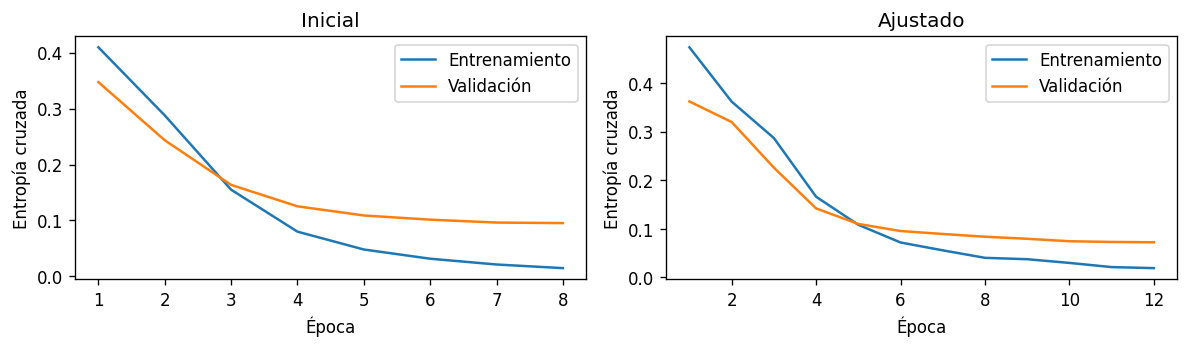

Se obtuvo un cambio de **+0.0235 en F1 de validación** al aplicar el ajuste. Se seleccionó el modelo **ajustado** con la regla fijada previamente. Las curvas permiten comprobar si la pérdida de entrenamiento disminuye mientras la de validación deja de mejorar.

In [7]:
# Se compararon las curvas para revisar el aprendizaje y el sobreajuste.
fig, ejes = plt.subplots(1, 2, figsize=(10, 3))
for ax, historia, titulo in zip(ejes, [hist_inicial.history, hist_ajustado.history], ["Inicial", "Ajustado"]):
    ax.plot(range(1, len(historia["loss"])+1), historia["loss"], label="Entrenamiento")
    ax.plot(range(1, len(historia["val_loss"])+1), historia["val_loss"], label="Validación")
    ax.set(title=titulo, xlabel="Época", ylabel="Entropía cruzada")
    ax.legend()
plt.tight_layout()
plt.savefig(BASE / "resultados/curvas_entrenamiento.png", dpi=140)
plt.show()
for nombre, hist in [("inicial", hist_inicial), ("ajustado", hist_ajustado)]:
    pd.DataFrame(hist.history).to_csv(BASE / f"resultados/historia_{nombre}.csv", index=False)
delta = metricas_ajustado["f1_spam"] - metricas_inicial["f1_spam"]
display(Markdown(f"Se obtuvo un cambio de **{delta:+.4f} en F1 de validación** al aplicar el ajuste. "
                 f"Se seleccionó el modelo **{elegido}** con la regla fijada previamente. "
                 "Las curvas permiten comprobar si la pérdida de entrenamiento disminuye mientras la de validación deja de mejorar."))

## Resultados
Se evaluó una sola vez la configuración elegida con el conjunto de prueba. Se reportó una referencia trivial que predice siempre `ham`, para mostrar por qué la accuracy aislada puede resultar engañosa en un problema desbalanceado. El test no se usó para seleccionar arquitectura ni umbral.


              precision    recall  f1-score   support

         ham     0.9853    0.9941    0.9897       675
        spam     0.9551    0.8947    0.9239        95

    accuracy                         0.9818       770
   macro avg     0.9702    0.9444    0.9568       770
weighted avg     0.9816    0.9818    0.9816       770

Ejemplos de errores:
Resultados guardados.


,accuracy,precision_spam,recall_spam,f1_spam,average_precision
Siempre ham,0.8766,0.0000,0.0000,0.0000,0.1234
CNN final,0.9818,0.9551,0.8947,0.9239,0.9557


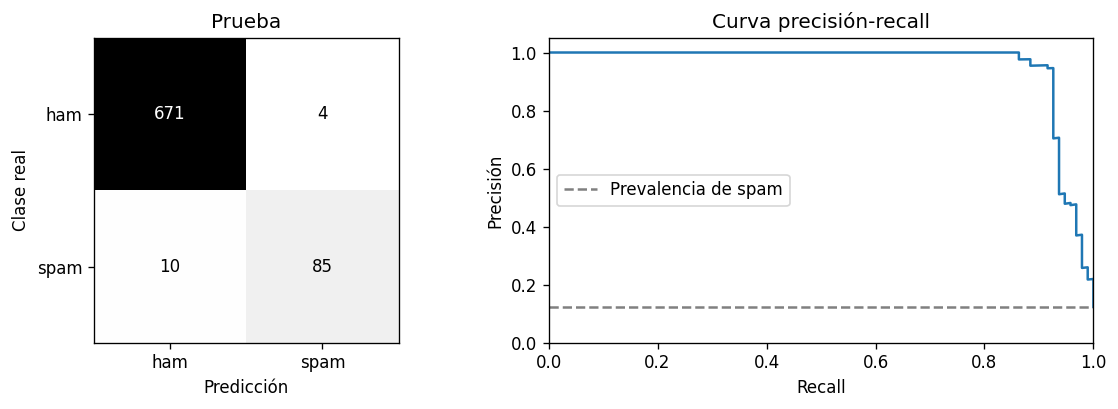

,clase,texto,puntuacion_spam,prediccion
2308,ham,"Madam,regret disturbance.might receive a refer...",0.804026,spam
4638,ham,My mobile number.pls sms ur mail id.convey reg...,0.730975,spam
1922,spam,TheMob>Yo yo yo-Here comes a new selection of ...,0.429036,ham
3243,spam,Not heard from U4 a while. Call me now am here...,0.007009,ham
4069,spam,Ur TONEXS subscription has been renewed and yo...,0.354447,ham
2152,spam,Back 2 work 2morro half term over! Can U C me ...,0.020351,ham


In [8]:
# Se evaluó el modelo elegido y se conservaron sus predicciones de prueba.
prob_test = mejor.predict(ds_test, verbose=0).ravel()
pred_test = (prob_test >= 0.5).astype(int)
metricas_test = medir(y_test, prob_test)
display(pd.DataFrame([medir(y_test, np.zeros(len(y_test))), metricas_test],
                     index=["Siempre ham", "CNN final"]).round(4))
print(classification_report(y_test, pred_test, target_names=["ham", "spam"], digits=4, zero_division=0))
fig, ejes = plt.subplots(1, 2, figsize=(10, 3.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=["ham", "spam"],
                                       cmap="Greys", ax=ejes[0], colorbar=False)
ejes[0].set(title="Prueba", xlabel="Predicción", ylabel="Clase real")
precision, recall, _ = precision_recall_curve(y_test, prob_test)
ejes[1].plot(recall, precision)
ejes[1].axhline(y_test.mean(), color="gray", linestyle="--", label="Prevalencia de spam")
ejes[1].set(xlabel="Recall", ylabel="Precisión", title="Curva precisión-recall", xlim=(0, 1), ylim=(0, 1.05))
ejes[1].legend()
plt.tight_layout()
plt.savefig(BASE / "resultados/evaluacion_prueba.png", dpi=140)
plt.show()
revision = prueba[["clase", "texto"]].copy()
revision["puntuacion_spam"] = prob_test
revision["prediccion"] = np.where(pred_test == 1, "spam", "ham")
revision.to_csv(BASE / "resultados/predicciones_prueba.csv", index=False)
print("Ejemplos de errores:")
display(revision[revision.clase.ne(revision.prediccion)].head(6))
resumen = {"modelo_elegido": elegido, "semilla": SEED, "umbral": 0.5,
           "prueba": metricas_test, "validacion": comparacion.drop(columns="segundos").to_dict("index"),
           "filas": {"originales": iniciales, "utilizadas": len(datos), "entrenamiento": len(entreno),
                     "validacion": len(validacion), "prueba": len(prueba)}}
(BASE / "resultados/metricas.json").write_text(json.dumps(resumen, indent=2), encoding="utf-8")
print("Resultados guardados.")

## Conclusiones
Se interpretan las métricas de la ejecución a continuación. La precisión mide qué fracción de los mensajes marcados como spam realmente lo eran; recall mide qué fracción del spam se detectó. Los falsos positivos pueden ocultar mensajes legítimos y los falsos negativos dejan pasar spam.


In [9]:
# Se redactó un resumen con los resultados medidos, sin introducir cifras manuales.
resultado_ajuste = ("mejoró" if delta > 0 else "no mejoró")
texto_ajuste = ("La mejora es compatible con una menor dependencia de patrones específicos del entrenamiento, "
    "aunque una sola partición no demuestra que esa sea la causa ni permite separar el efecto de cada cambio."
    if delta > 0 else "La hipótesis de mejora por regularización no se confirmó con este F1; se conservó la configuración con mejor validación.")
display(Markdown(f"""Se obtuvo **accuracy de {metricas_test['accuracy']:.2%}**, **F1 de spam de {metricas_test['f1_spam']:.4f}**, precisión de {metricas_test['precision_spam']:.2%} y recall de {metricas_test['recall_spam']:.2%} en prueba.

El ajuste {resultado_ajuste} el F1 de validación (cambio de {delta:+.4f}). {texto_ajuste}

Se retiraron duplicados antes de dividir los datos y se aprendió el vocabulario solamente del entrenamiento. Estas decisiones reducen fuga de información. Sin embargo, pueden permanecer mensajes casi idénticos y no se dispone de identificadores de remitente para separar por persona.

En esta ejecución, la pérdida de validación final fue menor con el ajuste que con la CNN inicial. Al final, la pérdida de entrenamiento también fue menor que la de validación en ambas configuraciones, por lo que sigue existiendo una brecha de generalización. Se alcanzaron las 12 épocas del modelo ajustado: early stopping estuvo configurado, pero no detuvo anticipadamente el entrenamiento. La mejora observada corresponde al ajuste conjunto de dropout y mayor duración de entrenamiento.

El corpus es histórico y está en inglés. No se comprobó su desempeño con SMS actuales, mensajes en español o fraudes nuevos. La puntuación sigmoid no está calibrada como probabilidad de fraude. Como mejoras se proponen validación con varias semillas, agrupación por plantillas, comparación con TF-IDF y un modelo lineal, y nuevos mensajes etiquetados. No se afirmó superioridad frente a esos métodos porque no se entrenaron aquí.
"""))

Se obtuvo **accuracy de 98.18%**, **F1 de spam de 0.9239**, precisión de 95.51% y recall de 89.47% en prueba.

El ajuste mejoró el F1 de validación (cambio de +0.0235). La mejora es compatible con una menor dependencia de patrones específicos del entrenamiento, aunque una sola partición no demuestra que esa sea la causa ni permite separar el efecto de cada cambio.

Se retiraron duplicados antes de dividir los datos y se aprendió el vocabulario solamente del entrenamiento. Estas decisiones reducen fuga de información. Sin embargo, pueden permanecer mensajes casi idénticos y no se dispone de identificadores de remitente para separar por persona.

En esta ejecución, la pérdida de validación final fue menor con el ajuste que con la CNN inicial. Al final, la pérdida de entrenamiento también fue menor que la de validación en ambas configuraciones, por lo que sigue existiendo una brecha de generalización. Se alcanzaron las 12 épocas del modelo ajustado: early stopping estuvo configurado, pero no detuvo anticipadamente el entrenamiento. La mejora observada corresponde al ajuste conjunto de dropout y mayor duración de entrenamiento.

El corpus es histórico y está en inglés. No se comprobó su desempeño con SMS actuales, mensajes en español o fraudes nuevos. La puntuación sigmoid no está calibrada como probabilidad de fraude. Como mejoras se proponen validación con varias semillas, agrupación por plantillas, comparación con TF-IDF y un modelo lineal, y nuevos mensajes etiquetados. No se afirmó superioridad frente a esos métodos porque no se entrenaron aquí.


## Aplicación
Se guardó un modelo completo `.keras` con vectorización, arquitectura y pesos. Recibe texto directamente. Se comprobó que cargar el archivo produce las mismas puntuaciones que el modelo en memoria. La aplicación utiliza mensajes nuevos en inglés; no es necesario volver a entrenar para ejecutar `predecir.py`.


In [10]:
# Se integró el preprocesamiento al modelo final para evitar inconsistencias al predecir.
entrada_texto = keras.Input(shape=(), dtype=tf.string, name="mensaje")
salida = mejor(vectorizador(entrada_texto))
modelo_final = keras.Model(entrada_texto, salida)
modelo_final.save(BASE / "modelos/modelo_final.keras")
recargado = keras.models.load_model(BASE / "modelos/modelo_final.keras")
mensajes = tf.constant(prueba.texto.head(5).to_numpy())
np.testing.assert_allclose(modelo_final(mensajes).numpy(), recargado(mensajes).numpy(), atol=1e-6)
from predecir import predecir_mensaje
ejemplos = ["Hey, are we still meeting for lunch tomorrow?",
            "Congratulations! You won a free prize. Call now to claim your cash reward!",
            "Please send me the notes after class."]
for mensaje in ejemplos:
    print(mensaje)
    print(predecir_mensaje(mensaje, recargado))
print("Se verificó la recarga del archivo .keras.")
print("Tamaño del modelo (MB):", round((BASE / "modelos/modelo_final.keras").stat().st_size / 1e6, 2))

Hey, are we still meeting for lunch tomorrow?
{'clase': 'ham', 'puntuacion_spam': 0.0016}
Congratulations! You won a free prize. Call now to claim your cash reward!
{'clase': 'spam', 'puntuacion_spam': 1.0}
Please send me the notes after class.
{'clase': 'ham', 'puntuacion_spam': 0.0004}
Se verificó la recarga del archivo .keras.
Tamaño del modelo (MB): 2.47


### Referencias y relación con las diapositivas
- Kaggle, UCI ML: [SMS Spam Collection](https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset).
- Almeida y Hidalgo: [fuente original UCI](https://archive.ics.uci.edu/dataset/228/sms+spam+collection), licencia CC BY 4.0.
- Keras: [clasificación de texto con Embedding y Conv1D](https://keras.io/examples/nlp/text_classification_from_scratch/). Se consultó como referencia del uso de convoluciones para texto; se usó otro dataset y una arquitectura más pequeña.
- Material de clase proporcionado: *03. Diagnosing Deep Neural Networks* (dropout y early stopping), *04 Convolutional Neural Networks* (convoluciones y pooling), *02. Fully Connected Neural Networks* (pérdida y optimización).

Para reproducir: instalar `requirements.txt` y ejecutar las celdas en orden desde la carpeta del proyecto. Los resultados pueden variar entre plataformas y versiones. No hace falta ejecutar el notebook para consultar las salidas guardadas o usar el modelo entregado.
